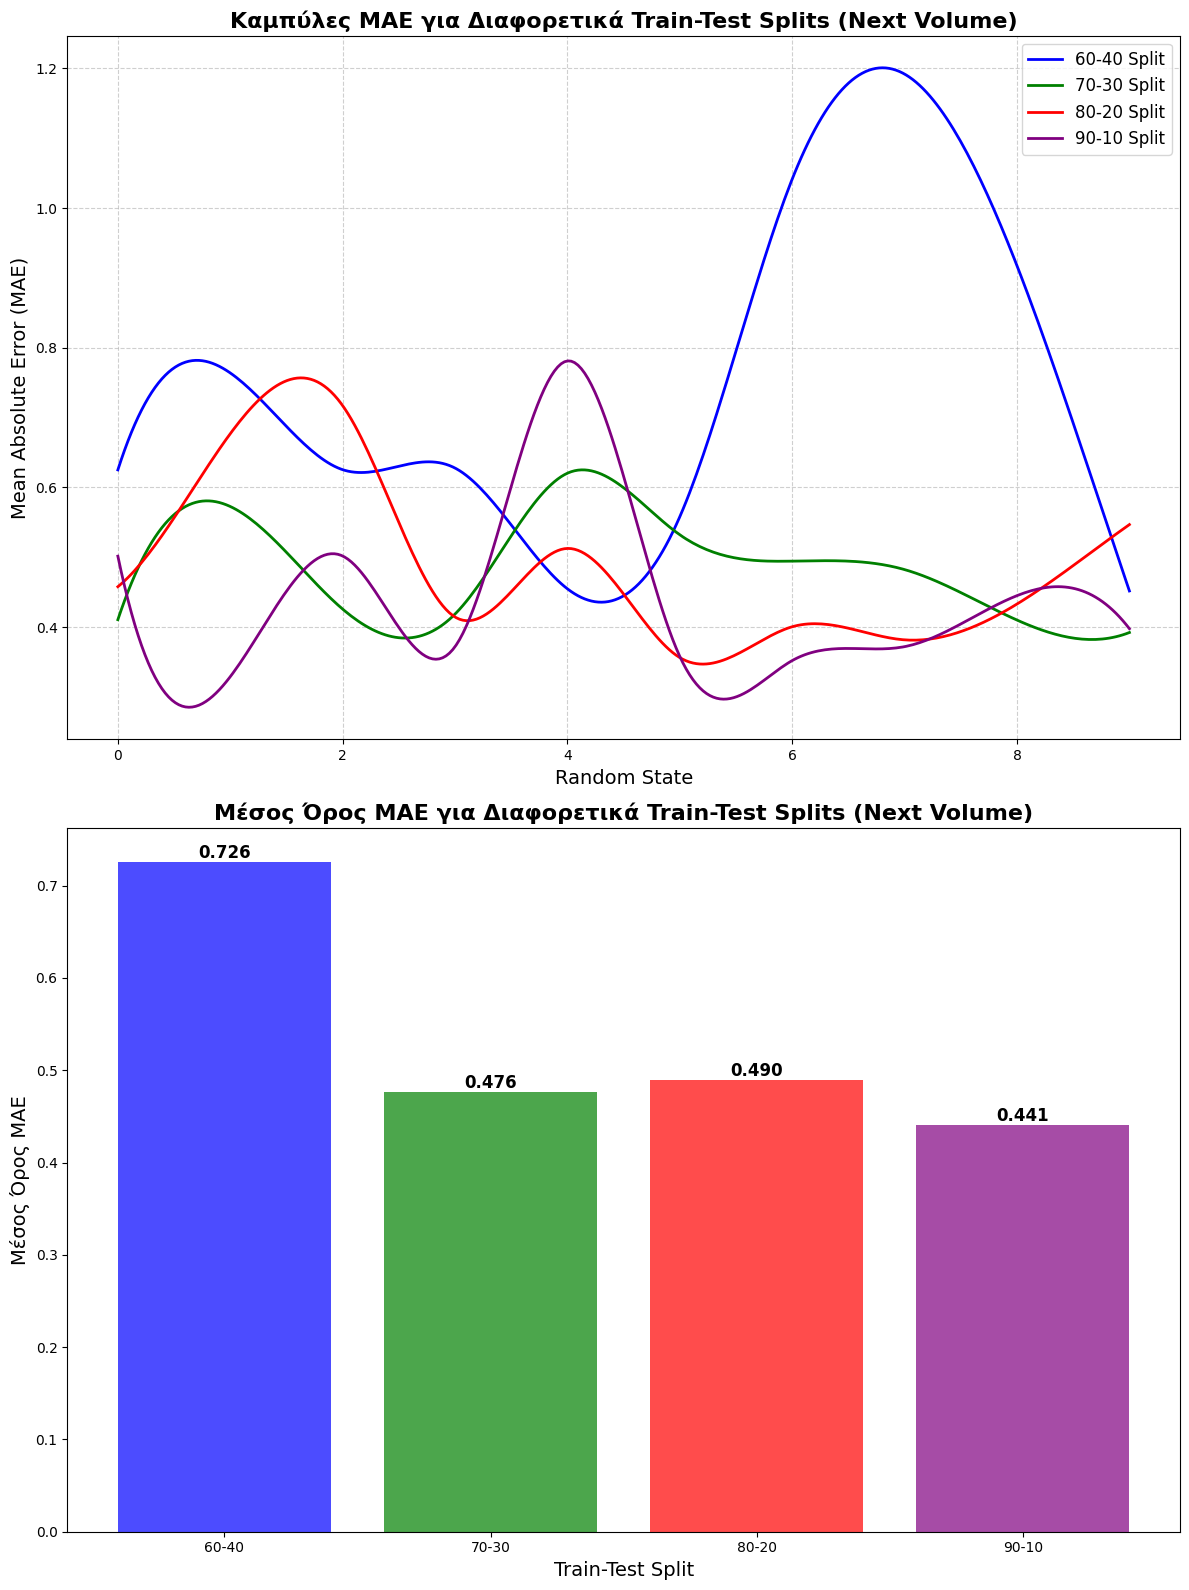

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.6251740013249126, 0.7639844012394262, 0.6254675456754006,
    0.6277992065302853, 0.45487707491667984, 0.5582234048203919,
    1.0416483742007772, 1.1918688025600657, 0.9174169051090258,
    0.451825375440914
])
mae_70_30 = np.array([
    0.4107003089613899, 0.5727694927740496, 0.4258229265802646,
    0.4187824633522353, 0.6204681745227851, 0.5322379948785656,
    0.4945227910479515, 0.48240501015472403, 0.41012881671382534,
    0.3923497642791098
])
mae_80_20 = np.array([
    0.45789196891440437, 0.6769680377595101, 0.7171822391532833,
    0.4145081264077852, 0.5127025283894358, 0.3563890877474461,
    0.4005927961134963, 0.38180824027335886, 0.43313042675086094,
    0.5468814197883234
])
mae_90_10 = np.array([
    0.5016634241585632, 0.32908425892878895, 0.5018888044292058,
    0.3720862481630807, 0.7811897452237331, 0.35796583737801274,
    0.3521798561358828, 0.37209788521426623, 0.44515194652785817,
    0.39776719599172156
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)

axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Next Volume)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Next Volume)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
